<a href="https://colab.research.google.com/github/papoochu/student-ai-learning-analysis/blob/main/notebooks/lda_nmf.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
from huggingface_hub import login
login()

#Load the StudyChat dataset
import pandas as pd
import numpy as np
import re

df = pd.read_json(
    "hf://datasets/wmcnicho/StudyChat/data.jsonl",
    lines=True
)

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())


Dataset shape: (16851, 13)
Columns: ['prompt', 'response', 'topic', 'messages', 'timestamp', 'chatId', 'userId', 'interactionCount', 'chatTitle', 'chatStartTime', 'chatTotalInteractionCount', 'llm_label', 'semester']


In [3]:

# Recreate the modeling corpus

corpus = df.copy()

# Keep prompts containing text
corpus["prompt"] = corpus["prompt"].fillna("").astype(str)
corpus = corpus[
    corpus["prompt"].str.strip() != ""
].copy()

# Calculate prompt length
corpus["word_count"] = (
    corpus["prompt"].str.split().str.len()
)

# Match the length threshold from Notebook 01
modeling_corpus = corpus[
    corpus["word_count"] <= 1000
].copy()

print("Nonempty prompts:", len(corpus))
print("Modeling corpus:", len(modeling_corpus))
print("Excluded long prompts:", len(corpus) - len(modeling_corpus))


Nonempty prompts: 16850
Modeling corpus: 16597
Excluded long prompts: 253


In [4]:

#Preprocess student prompts

from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
import re

stop_words_v2 = set(ENGLISH_STOP_WORDS)

def preprocess_text_v2(text):
    text = text.lower()

    # Preserve programming identifiers and underscores
    tokens = re.findall(
        r"\b[a-z_][a-z0-9_]*\b",
        text
    )

    # Remove stop words and very short tokens
    tokens = [
        word for word in tokens
        if word not in stop_words_v2 and len(word) > 2
    ]

    return " ".join(tokens)

modeling_corpus["processed_text_v2"] = (
    modeling_corpus["prompt"].apply(preprocess_text_v2)
)

print("Documents processed:", len(modeling_corpus))

# Show a few examples
for i in range(3):
    print(f"\nOriginal: {modeling_corpus.iloc[i]['prompt'][:150]}")
    print(f"Processed: {modeling_corpus.iloc[i]['processed_text_v2'][:150]}")


Documents processed: 16597

Original: cross validation tests it on multiple sets, so does it randomly select data on my dataset? concise
Processed: cross validation tests multiple sets does randomly select data dataset concise

Original: ### Report on findings/significance for Polynomial Regression
- Mean Squared Error (MSE): 0.00
- R-squared Score: 1.0000
- Cross-validation R-squared 
Processed: report findings significance polynomial regression mean squared error mse squared score cross validation squared scores average squared score metrics 

Original: what is KCL or KCI
Processed: kcl kci


In [5]:

#Create document-term matrices for LDA and NMF

from sklearn.feature_extraction.text import (
    CountVectorizer,
    TfidfVectorizer
)

# Match the vectorizer settings from Notebook 01
count_vect = CountVectorizer(
    max_df=0.8,
    min_df=5,
    max_features=5000,
    ngram_range=(1, 2)
)

tfidf_vect = TfidfVectorizer(
    max_df=0.8,
    min_df=5,
    max_features=5000,
    ngram_range=(1, 2),
    sublinear_tf=True
)

# Create both matrices
X_count = count_vect.fit_transform(
    modeling_corpus["processed_text_v2"].fillna("")
)

X_tfidf = tfidf_vect.fit_transform(
    modeling_corpus["processed_text_v2"].fillna("")
)

print("LDA count matrix:", X_count.shape)
print("NMF TF-IDF matrix:", X_tfidf.shape)


LDA count matrix: (16597, 5000)
NMF TF-IDF matrix: (16597, 5000)


## LDA Modeling

In [6]:

# Train an initial LDA model
# Adapted from the course LDA notebook

from sklearn.decomposition import LatentDirichletAllocation

n_topics = 5

LDA_model = LatentDirichletAllocation(
    n_components=n_topics,
    random_state=42,
    learning_method="batch",
    max_iter=10,
    n_jobs=-1
)

LDA_model.fit(X_count)

print("LDA model trained successfully!")
print("Number of topics:", n_topics)
print("Perplexity:", LDA_model.perplexity(X_count))


LDA model trained successfully!
Number of topics: 5
Perplexity: 862.0539192771596


In [7]:
#Display the top 10 words for each LDA topic

feature_names = count_vect.get_feature_names_out()

for topic_idx, topic in enumerate(LDA_model.components_):

    top_indices = topic.argsort()[-10:][::-1]
    top_words = feature_names[top_indices]

    print(f"\nTopic {topic_idx + 1}:")
    print(", ".join(top_words))


Topic 1:
false, true, true false, false true, false false, self, redacted, true true, torch, hidden

Topic 2:
loss, epoch, self, epoch loss, model, loss epoch, optimizer, packages, feature, todo

Topic 3:
model, temperature, print, dataset, blood, cell, count, start_text, text, rows

Topic 4:
node, char, sequence, prefix, tables, self, children, document, character, def

Topic 5:
tensor, print, model, use, data, score, shape, mean, torch, dataset


In [12]:
!pip install gensim

# Compare LDA topic counts using two metrics

from sklearn.decomposition import LatentDirichletAllocation
from gensim.models.coherencemodel import CoherenceModel
from gensim.corpora import Dictionary
import pandas as pd

# Use the same preprocessed documents
tokenized_docs = [
    text.split()
    for text in modeling_corpus["processed_text_v2"].fillna("")
]

dictionary = Dictionary(tokenized_docs)
bow_corpus = [
    dictionary.doc2bow(doc)
    for doc in tokenized_docs
]

feature_names = count_vect.get_feature_names_out()

# Test multiple topic counts
topic_counts = [2, 3, 5, 8, 10]
lda_results = []

for k in topic_counts:

    model = LatentDirichletAllocation(
        n_components=k,
        random_state=42,
        learning_method="batch",
        max_iter=10,
        n_jobs=-1
    )

    model.fit(X_count)

    # Lower perplexity is better
    perplexity = model.perplexity(X_count)

    # Select the top 10 unigrams per topic
    topics = []

    for topic in model.components_:
        ranked_indices = topic.argsort()[::-1]

        top_words = [
            feature_names[i]
            for i in ranked_indices
            if " " not in feature_names[i]
        ][:10]

        topics.append(top_words)

    # Higher UMass coherence is better
    coherence_model = CoherenceModel(
        topics=topics,
        corpus=bow_corpus,
        dictionary=dictionary,
        coherence="u_mass"
    )

    coherence = coherence_model.get_coherence()

    lda_results.append({
        "Topics": k,
        "Perplexity": perplexity,
        "UMass_Coherence": coherence
    })

    print(
        f"k={k}: "
        f"Perplexity={perplexity:.2f}, "
        f"UMass={coherence:.4f}"
    )

lda_results_df = pd.DataFrame(lda_results)

display(lda_results_df)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 65.4 MB/s  0:00:00
k=2: Perplexity=1503.51, UMass=-2.6355
k=3: Perplexity=1188.51, UMass=-2.0347
k=5: Perplexity=862.05, UMass=-2.4718
k=8: Perplexity=618.19, UMass=-2.3649
k=10: Perplexity=548.73, UMass=-1.9518


,Topics,Perplexity,UMass_Coherence
0,2,1503.513974,-2.635491
1,3,1188.505522,-2.034679
2,5,862.053919,-2.471786
3,8,618.185525,-2.364889
4,10,548.727128,-1.951849


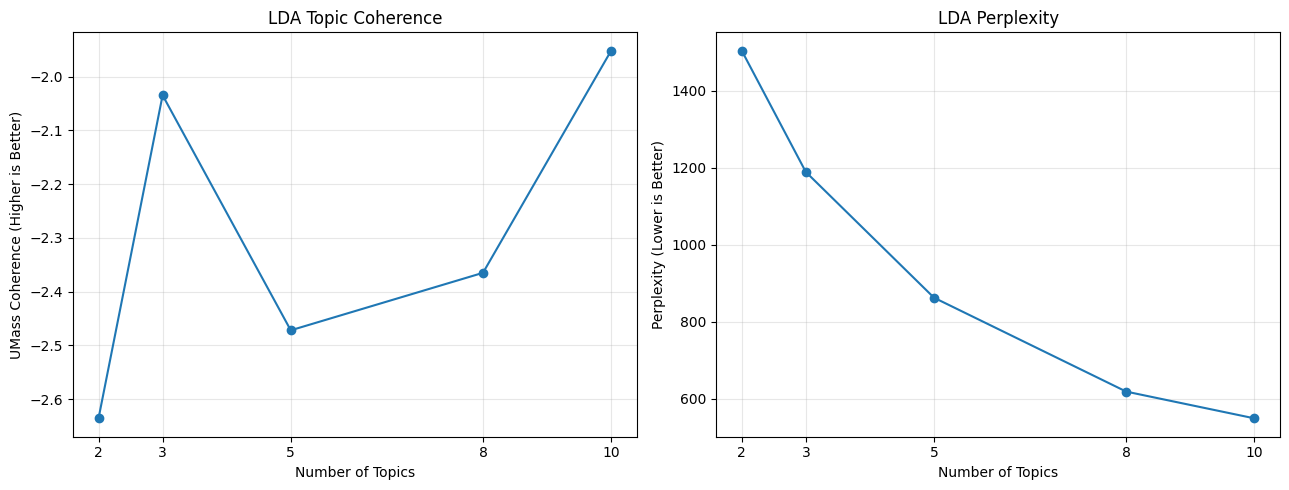

In [13]:

#Plot LDA evaluation metrics

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Plot 1: UMass Coherence
axes[0].plot(
    lda_results_df["Topics"],
    lda_results_df["UMass_Coherence"],
    marker="o"
)

axes[0].set_title("LDA Topic Coherence")
axes[0].set_xlabel("Number of Topics")
axes[0].set_ylabel("UMass Coherence (Higher is Better)")
axes[0].set_xticks(lda_results_df["Topics"])
axes[0].grid(True, alpha=0.3)

# Plot 2: Perplexity
axes[1].plot(
    lda_results_df["Topics"],
    lda_results_df["Perplexity"],
    marker="o"
)

axes[1].set_title("LDA Perplexity")
axes[1].set_xlabel("Number of Topics")
axes[1].set_ylabel("Perplexity (Lower is Better)")
axes[1].set_xticks(lda_results_df["Topics"])
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


In [14]:

#Extend LDA topic-number evaluation

additional_counts = [12, 15, 20]

for k in additional_counts:
    model = LatentDirichletAllocation(
        n_components=k,
        random_state=42,
        learning_method="batch",
        max_iter=10,
        n_jobs=-1
    )

    model.fit(X_count)
    perplexity = model.perplexity(X_count)

    topics = []

    for topic in model.components_:
        ranked_indices = topic.argsort()[::-1]

        top_words = [
            feature_names[i]
            for i in ranked_indices
            if " " not in feature_names[i]
        ][:10]

        topics.append(top_words)

    coherence = CoherenceModel(
        topics=topics,
        corpus=bow_corpus,
        dictionary=dictionary,
        coherence="u_mass"
    ).get_coherence()

    lda_results.append({
        "Topics": k,
        "Perplexity": perplexity,
        "UMass_Coherence": coherence
    })

lda_results_df = pd.DataFrame(lda_results).sort_values("Topics")

display(lda_results_df)


,Topics,Perplexity,UMass_Coherence
0,2,1503.513974,-2.635491
1,3,1188.505522,-2.034679
2,5,862.053919,-2.471786
3,8,618.185525,-2.364889
4,10,548.727128,-1.951849
5,12,501.525727,-2.149807
6,15,446.618560,-1.884355
7,20,385.264059,-2.247029


In [15]:

# Fine-tune LDA between 10 and 15 topics

additional_counts = [11, 13, 14]

for k in additional_counts:
    model = LatentDirichletAllocation(
        n_components=k,
        random_state=42,
        learning_method="batch",
        max_iter=10,
        n_jobs=-1
    )

    model.fit(X_count)

    # Metric 1: Training perplexity
    perplexity = model.perplexity(X_count)

    # Select the 10 highest-weighted unigrams per topic
    topics = []

    for topic in model.components_:
        ranked_indices = topic.argsort()[::-1]

        top_words = [
            feature_names[i]
            for i in ranked_indices
            if " " not in feature_names[i]
        ][:10]

        topics.append(top_words)

    # Metric 2: UMass topic coherence
    coherence = CoherenceModel(
        topics=topics,
        corpus=bow_corpus,
        dictionary=dictionary,
        coherence="u_mass"
    ).get_coherence()

    lda_results.append({
        "Topics": k,
        "Perplexity": perplexity,
        "UMass_Coherence": coherence
    })

    print(
        f"k={k}: "
        f"Perplexity={perplexity:.2f}, "
        f"UMass={coherence:.4f}"
    )

# Sort results by number of topics
lda_results_df = (
    pd.DataFrame(lda_results)
    .drop_duplicates(subset="Topics", keep="last")
    .sort_values("Topics")
    .reset_index(drop=True)
)

# Display the range we're investigating
display(
    lda_results_df[
        lda_results_df["Topics"].between(10, 15)
    ]
)


k=11: Perplexity=514.42, UMass=-1.8269
k=13: Perplexity=479.20, UMass=-2.3419
k=14: Perplexity=458.19, UMass=-2.2227


,Topics,Perplexity,UMass_Coherence
4,10,548.727128,-1.951849
5,11,514.416695,-1.826935
6,12,501.525727,-2.149807
7,13,479.199123,-2.341878
8,14,458.191782,-2.222723
9,15,446.618560,-1.884355


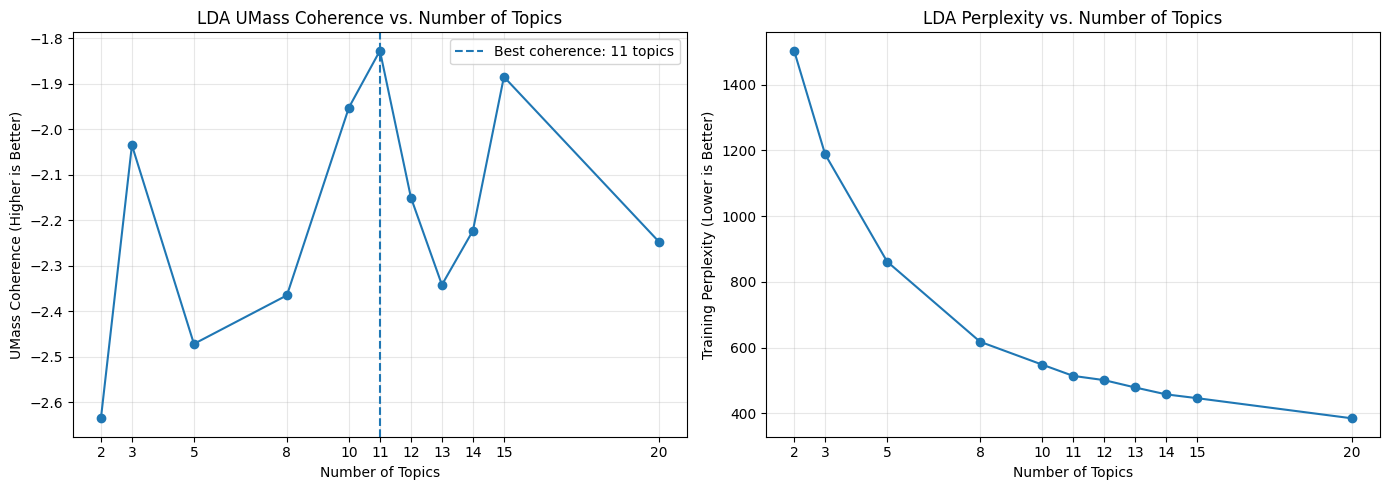

In [16]:

# Plot LDA topic count vs. UMass coherence and perplexity

import matplotlib.pyplot as plt
import pandas as pd

# Include all topic counts tested so far
plot_df = (
    pd.DataFrame(lda_results)
    .drop_duplicates(subset="Topics", keep="last")
    .sort_values("Topics")
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Graph 1: UMass coherence
axes[0].plot(
    plot_df["Topics"],
    plot_df["UMass_Coherence"],
    marker="o"
)

axes[0].axvline(
    x=11, linestyle="--",
    label="Best coherence: 11 topics"
)

axes[0].set_title("LDA UMass Coherence vs. Number of Topics")
axes[0].set_xlabel("Number of Topics")
axes[0].set_ylabel("UMass Coherence (Higher is Better)")
axes[0].set_xticks(plot_df["Topics"])
axes[0].grid(True, alpha=0.3)
axes[0].legend()

# Graph 2: Perplexity
axes[1].plot(
    plot_df["Topics"],
    plot_df["Perplexity"],
    marker="o"
)

axes[1].set_title("LDA Perplexity vs. Number of Topics")
axes[1].set_xlabel("Number of Topics")
axes[1].set_ylabel("Training Perplexity (Lower is Better)")
axes[1].set_xticks(plot_df["Topics"])
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


In [17]:

# Examine the 11-topic LDA model

from sklearn.decomposition import LatentDirichletAllocation
import pandas as pd

lda_11 = LatentDirichletAllocation(
    n_components=11,
    random_state=42,
    learning_method="batch",
    max_iter=10,
    n_jobs=-1
)

lda_11.fit(X_count)

feature_names = count_vect.get_feature_names_out()

topic_summary_11 = []

for topic_id, topic in enumerate(lda_11.components_):

    top_indices = topic.argsort()[-10:][::-1]

    topic_summary_11.append({
        "Topic": topic_id + 1,
        "Top Words": ", ".join(feature_names[top_indices])
    })

topic_summary_11_df = pd.DataFrame(topic_summary_11)

display(topic_summary_11_df)


,Topic,Top Words
0,1,"redacted, file, assignment, line, users, users..."
1,2,"feature, yes, packages, site, site packages, l..."
2,3,"temperature, blood, cell, start_text, count, l..."
3,4,"sequence, tables, probability, character, char..."
4,5,"dataset, data, notpresent, print, mean, regres..."
5,6,"tensor, print, dataset, shape, torch, rows, co..."
6,7,"node, self, prefix, char, children, suggestion..."
7,8,"loss, epoch, epoch loss, torch, loss epoch, mo..."
8,9,"false, true, true false, false true, false fal..."
9,10,"model, score, training, sklearn, set, sample, ..."


In [19]:

# Train and inspect the 15-topic LDA model

from sklearn.decomposition import LatentDirichletAllocation
import pandas as pd

lda_15 = LatentDirichletAllocation(
    n_components=15,
    random_state=42,
    learning_method="batch",
    max_iter=10,
    n_jobs=-1
)

lda_15.fit(X_count)

feature_names = count_vect.get_feature_names_out()

topics_15 = []

for topic_id, topic in enumerate(lda_15.components_):
    top_indices = topic.argsort()[-10:][::-1]

    topics_15.append({
        "Topic": topic_id + 1,
        "Top Words": ", ".join(feature_names[top_indices])
    })

topic_summary_15_df = pd.DataFrame(topics_15)

display(topic_summary_15_df)



,Topic,Top Words
0,1,"redacted, assignment, users, users redacted, l..."
1,2,"packages, self, site, site packages, lib, pyth..."
2,3,"temperature, start_text, logits, model, input,..."
3,4,"sequence, text, table, updated, probability, u..."
4,5,"notpresent, mean, cross, validation, neural, s..."
5,6,"tables, sequence, probability, character, freq..."
6,7,"node, self, prefix, char, children, suggestion..."
7,8,"loss, epoch, epoch loss, loss epoch, model, to..."
8,9,"code, use, file, tree, data, test, python, aut..."
9,10,"model, score, print, sample, sklearn, intercep..."


In [20]:

#Inspect representative prompts for each LDA topic

import numpy as np
import pandas as pd

# Get topic probabilities for each student prompt
topic_probabilities = lda_11.transform(X_count)

# Assign each prompt to its highest-probability topic
dominant_topics = topic_probabilities.argmax(axis=1)

rng = np.random.default_rng(42)

samples = []

for topic_id in range(11):

    indices = np.where(dominant_topics == topic_id)[0]

    if len(indices) == 0:
        continue

    selected = rng.choice(
        indices,
        size=min(3, len(indices)),
        replace=False
    )

    for idx in selected:
        samples.append({
            "Topic": topic_id + 1,
            "Probability": round(
                topic_probabilities[idx, topic_id], 3
            ),
            "Prompt": modeling_corpus.iloc[idx]["prompt"][:300]
        })

samples_df = pd.DataFrame(samples)

display(samples_df)


,Topic,Probability,Prompt
0,1,0.464,"For this tree, I have these words:\n\nthere th..."
1,1,0.617,When I run use suggest_ucs and run main.py I g...
2,1,0.091,genarized it
3,2,0.788,# Converted SQL to Pandas code\n\ndata = {\n ...
4,2,0.791,Grouped dataset: \n <pandas.core.groupby.gener...
5,2,0.545,still facing the same errors
6,3,0.992,"def sample_from_output(logits, temperature=1.0..."
7,3,0.993,from the column name above I want to replace s...
8,3,0.424,How can I pull just column names from a df?
9,4,0.864,what does each table capturing character frequ...


### LDA Topic Interpretation and Model Selection

LDA models containing 2 to 20 topics were evaluated using training perplexity and UMass topic coherence. Among the tested configurations, the 11-topic model achieved the highest coherence score (−1.8269), with a perplexity of 514.42.

A qualitative evaluation was performed using 33 randomly sampled student prompts, with three prompts sampled from each dominant topic.

Several topics were relatively interpretable, including character-level language modeling, regression, search algorithms, and neural network implementation. However, other topics mixed unrelated requests or appeared influenced by pasted code, assignment instructions, and dataset-specific vocabulary.

Some short prompts also lacked sufficient context for reliable interpretation. High topic probabilities did not always correspond to meaningful topic assignments.

The 11-topic configuration was selected because of its coherence score, relatively simple structure, and several recognizable topics. Further hyperparameter refinement and comparison with NMF and BERTopic will help assess the strengths and limitations of the LDA results.

Overall, LDA was more successful at identifying academic subjects and technical vocabulary than the specific types of educational assistance students requested.

In [21]:

# LDA hyperparameter tuning

from sklearn.decomposition import LatentDirichletAllocation
from gensim.models.coherencemodel import CoherenceModel
import pandas as pd

lda_settings = [
    {"name": "Baseline", "alpha": None, "beta": None},
    {"name": "Sparse", "alpha": 0.1, "beta": 0.1},
    {"name": "Very sparse", "alpha": 0.01, "beta": 0.01}
]

tuning_results = []
tuned_lda_models = {}

for setting in lda_settings:

    model = LatentDirichletAllocation(
        n_components=11,
        doc_topic_prior=setting["alpha"],
        topic_word_prior=setting["beta"],
        random_state=42,
        learning_method="batch",
        max_iter=10,
        n_jobs=-1
    )

    model.fit(X_count)

    # Keep each trained model for later inspection
    tuned_lda_models[setting["name"]] = model

    # Calculate training perplexity
    perplexity = model.perplexity(X_count)

    # Extract 10 unigrams per topic
    topics = []

    for topic in model.components_:
        ranked_indices = topic.argsort()[::-1]

        top_words = [
            feature_names[i]
            for i in ranked_indices
            if " " not in feature_names[i]
        ][:10]

        topics.append(top_words)

    # Calculate UMass coherence
    coherence = CoherenceModel(
        topics=topics,
        corpus=bow_corpus,
        dictionary=dictionary,
        coherence="u_mass"
    ).get_coherence()

    tuning_results.append({
        "Setting": setting["name"],
        "Alpha": setting["alpha"],
        "Beta": setting["beta"],
        "Perplexity": perplexity,
        "UMass_Coherence": coherence
    })

tuning_df = pd.DataFrame(tuning_results)

display(tuning_df)


,Setting,Alpha,Beta,Perplexity,UMass_Coherence
0,Baseline,NaN,NaN,514.416695,-1.826935
1,Sparse,0.10,0.10,516.229763,-1.826935
2,Very sparse,0.01,0.01,510.906003,-1.884200


### LDA Hyperparameter Optimization

After selecting 11 topics provisionally, three configurations of the document-topic prior (alpha) and topic-word prior (beta) were evaluated.

The baseline model achieved a UMass coherence of −1.8269 and training perplexity of 514.42. The sparse configuration (alpha = 0.1, beta = 0.1) produced identical coherence but slightly higher perplexity (516.23).

The very sparse configuration (alpha = 0.01, beta = 0.01) achieved the lowest training perplexity (510.91), but its coherence decreased to −1.8842.

The baseline configuration was selected provisionally because it achieved the highest coherence, tied with the sparse configuration, while maintaining better perplexity than the sparse alternative.

Although several topics were interpretable, others remained influenced by programming syntax, repeated assignments, and dataset-specific vocabulary. These limitations will be considered when comparing LDA with NMF and BERTopic.

## NMF Modeling

In [23]:

#Train baseline NMF
# Adapted from the course NMF notebook

from sklearn.decomposition import NMF
import numpy as np

kTopics = 5

nmf_model = NMF(
    n_components=kTopics,
    init="nndsvdar",
    solver="cd",
    beta_loss="frobenius",
    tol=1e-4,
    max_iter=500,
    random_state=42,
    alpha_W=0.001,
    alpha_H=0.001,
    l1_ratio=0.5,
    verbose=0,
    shuffle=False
)

# Reuse our StudyChat TF-IDF matrix
W = nmf_model.fit_transform(X_tfidf)
H = nmf_model.components_

print("NMF model trained successfully!")
print("W (document-topic matrix):", W.shape)
print("H (topic-term matrix):", H.shape)
print("Reconstruction error:", nmf_model.reconstruction_err_)



NMF model trained successfully!
W (document-topic matrix): (16597, 5)
H (topic-term matrix): (5, 5000)
Reconstruction error: 127.26743495490106


In [28]:

# Check whether NMF topic weights collapsed

import numpy as np

print("H matrix shape:", H.shape)
print("Minimum H weight:", H.min())
print("Maximum H weight:", H.max())

print("\nNonzero words per topic:")
for topic_id, topic in enumerate(H):
    nonzero_count = np.count_nonzero(topic)

    print(
        f"Topic {topic_id + 1}: "
        f"{nonzero_count} nonzero words, "
        f"maximum weight = {topic.max():.6f}"
    )

print("\nNumber of documents with all-zero W weights:")
print(np.sum(np.all(W == 0, axis=1)))


H matrix shape: (5, 5000)
Minimum H weight: 0.0
Maximum H weight: 0.0

Nonzero words per topic:
Topic 1: 0 nonzero words, maximum weight = 0.000000
Topic 2: 0 nonzero words, maximum weight = 0.000000
Topic 3: 0 nonzero words, maximum weight = 0.000000
Topic 4: 0 nonzero words, maximum weight = 0.000000
Topic 5: 0 nonzero words, maximum weight = 0.000000

Number of documents with all-zero W weights:
16597


In [29]:

#Retrain NMF without regularization

from sklearn.decomposition import NMF
import numpy as np

nmf_model = NMF(
    n_components=5,
    init="nndsvdar",
    solver="cd",
    beta_loss="frobenius",
    tol=1e-4,
    max_iter=500,
    random_state=42,
    alpha_W=0.0,
    alpha_H=0.0,
    l1_ratio=0.0,
    verbose=0,
    shuffle=False
)

W = nmf_model.fit_transform(X_tfidf)
H = nmf_model.components_

print("NMF model trained successfully!")
print("W shape:", W.shape)
print("H shape:", H.shape)
print("Reconstruction error:", nmf_model.reconstruction_err_)

print("\nNonzero words per topic:")

for topic_id, topic in enumerate(H):
    print(
        f"Topic {topic_id + 1}: "
        f"{np.count_nonzero(topic)} nonzero words, "
        f"max weight = {topic.max():.6f}"
    )

print("\nDocuments with all-zero topic weights:")
print(np.sum(np.all(W == 0, axis=1)))


NMF model trained successfully!
W shape: (16597, 5)
H shape: (5, 5000)
Reconstruction error: 123.32093033010314

Nonzero words per topic:
Topic 1: 3171 nonzero words, max weight = 1.573850
Topic 2: 3794 nonzero words, max weight = 0.927531
Topic 3: 3045 nonzero words, max weight = 0.976488
Topic 4: 1686 nonzero words, max weight = 1.165166
Topic 5: 2255 nonzero words, max weight = 0.609510

Documents with all-zero topic weights:
400


In [30]:
# Display top words for each NMF topic

import pandas as pd

feature_names_nmf = tfidf_vect.get_feature_names_out()

nmf_topics = []

for topic_id, topic in enumerate(H):
    top_indices = topic.argsort()[-10:][::-1]

    nmf_topics.append({
        "Topic": topic_id + 1,
        "Top Words": ", ".join(
            feature_names_nmf[top_indices]
        )
    })

nmf_topics_df = pd.DataFrame(nmf_topics)
display(nmf_topics_df)

,Topic,Top Words
0,1,"node, self, children, char, prefix, node child..."
1,2,"score, model, use, does, sklearn, training, pr..."
2,3,"tables, sequence, probability, frequency, freq..."
3,4,"query, count, target, sql, sql query, target c..."
4,5,"blood, columns, age, dataset, cell, column, bg..."


In [31]:

# Evaluate NMF topic counts
# Metrics: reconstruction error and UMass coherence

from sklearn.decomposition import NMF
from gensim.models.coherencemodel import CoherenceModel
from gensim.corpora import Dictionary
import pandas as pd

# Prepare documents for UMass coherence
tokenized_docs = [
    text.split()
    for text in modeling_corpus["processed_text_v2"].fillna("")
]

dictionary = Dictionary(tokenized_docs)

bow_corpus = [
    dictionary.doc2bow(doc)
    for doc in tokenized_docs
]

feature_names_nmf = tfidf_vect.get_feature_names_out()

topic_counts = [3, 5, 8, 10, 15]
nmf_results = []

for k in topic_counts:

    model = NMF(
        n_components=k,
        init="nndsvdar",
        solver="cd",
        beta_loss="frobenius",
        tol=1e-4,
        max_iter=500,
        random_state=42,
        alpha_W=0.0,
        alpha_H=0.0,
        l1_ratio=0.0,
        shuffle=False
    )

    model.fit(X_tfidf)

    # Metric 1: Reconstruction error
    reconstruction_error = model.reconstruction_err_

    # Extract top 10 unigrams for each topic
    topics = []

    for topic in model.components_:
        ranked_indices = topic.argsort()[::-1]

        top_words = [
            feature_names_nmf[i]
            for i in ranked_indices
            if " " not in feature_names_nmf[i]
        ][:10]

        topics.append(top_words)

    # Metric 2: UMass topic coherence
    coherence = CoherenceModel(
        topics=topics,
        corpus=bow_corpus,
        dictionary=dictionary,
        coherence="u_mass"
    ).get_coherence()

    nmf_results.append({
        "Topics": k,
        "Reconstruction_Error": reconstruction_error,
        "UMass_Coherence": coherence
    })

    print(
        f"k={k}: "
        f"Reconstruction Error={reconstruction_error:.4f}, "
        f"UMass={coherence:.4f}"
    )

nmf_results_df = pd.DataFrame(nmf_results)

display(nmf_results_df)


k=3: Reconstruction Error=124.5931, UMass=-1.0995
k=5: Reconstruction Error=123.3209, UMass=-0.9980
k=8: Reconstruction Error=121.7610, UMass=-1.2487
k=10: Reconstruction Error=120.8358, UMass=-1.3909
k=15: Reconstruction Error=118.8191, UMass=-1.3289


,Topics,Reconstruction_Error,UMass_Coherence
0,3,124.593141,-1.099467
1,5,123.320930,-0.997979
2,8,121.761019,-1.248748
3,10,120.835782,-1.390883
4,15,118.819110,-1.328911


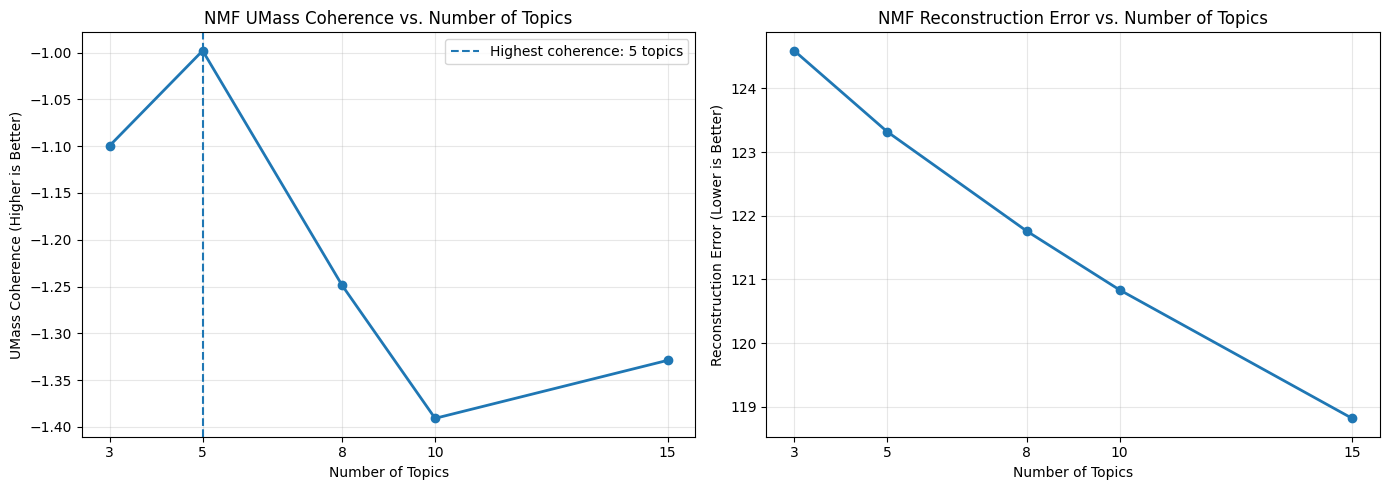

In [32]:

# Graph NMF topic-number optimization

import matplotlib.pyplot as plt

# Sort by number of topics
plot_df = nmf_results_df.sort_values("Topics")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Graph 1: UMass coherence
axes[0].plot(
    plot_df["Topics"],
    plot_df["UMass_Coherence"],
    marker="o",
    linewidth=2
)

axes[0].axvline(
    x=5,
    linestyle="--",
    label="Highest coherence: 5 topics"
)

axes[0].set_title("NMF UMass Coherence vs. Number of Topics")
axes[0].set_xlabel("Number of Topics")
axes[0].set_ylabel("UMass Coherence (Higher is Better)")
axes[0].set_xticks(plot_df["Topics"])
axes[0].grid(True, alpha=0.3)
axes[0].legend()

# Graph 2: Reconstruction error
axes[1].plot(
    plot_df["Topics"],
    plot_df["Reconstruction_Error"],
    marker="o",
    linewidth=2
)

axes[1].set_title("NMF Reconstruction Error vs. Number of Topics")
axes[1].set_xlabel("Number of Topics")
axes[1].set_ylabel("Reconstruction Error (Lower is Better)")
axes[1].set_xticks(plot_df["Topics"])
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


In [33]:

#Evaluate NMF with 4, 6, and 7 topics

additional_counts = [4, 6, 7]

for k in additional_counts:

    model = NMF(
        n_components=k,
        init="nndsvdar",
        solver="cd",
        beta_loss="frobenius",
        tol=1e-4,
        max_iter=500,
        random_state=42,
        alpha_W=0.0,
        alpha_H=0.0,
        l1_ratio=0.0,
        shuffle=False
    )

    model.fit(X_tfidf)

    reconstruction_error = model.reconstruction_err_

    # Select the 10 highest-weighted unigrams per topic
    topics = []

    for topic in model.components_:
        ranked_indices = topic.argsort()[::-1]

        top_words = [
            feature_names_nmf[i]
            for i in ranked_indices
            if " " not in feature_names_nmf[i]
        ][:10]

        topics.append(top_words)

    coherence = CoherenceModel(
        topics=topics,
        corpus=bow_corpus,
        dictionary=dictionary,
        coherence="u_mass"
    ).get_coherence()

    nmf_results.append({
        "Topics": k,
        "Reconstruction_Error": reconstruction_error,
        "UMass_Coherence": coherence
    })

    print(
        f"k={k}: "
        f"Reconstruction Error={reconstruction_error:.4f}, "
        f"UMass={coherence:.4f}"
    )

# Update the results table
nmf_results_df = (
    pd.DataFrame(nmf_results)
    .drop_duplicates(subset="Topics", keep="last")
    .sort_values("Topics")
    .reset_index(drop=True)
)

display(nmf_results_df)


k=4: Reconstruction Error=123.9216, UMass=-1.1047
k=6: Reconstruction Error=122.7429, UMass=-1.0582
k=7: Reconstruction Error=122.2456, UMass=-1.1227


,Topics,Reconstruction_Error,UMass_Coherence
0,3,124.593141,-1.099467
1,4,123.921643,-1.104741
2,5,123.320930,-0.997979
3,6,122.742896,-1.058176
4,7,122.245606,-1.122742
5,8,121.761019,-1.248748
6,10,120.835782,-1.390883
7,15,118.819110,-1.328911


In [34]:

#Inspect student prompts assigned to NMF topics

import numpy as np
import pandas as pd

# W comes from our corrected 5-topic NMF model
dominant_topics = W.argmax(axis=1)

# Identify documents with meaningful topic weights
nonzero_documents = W.sum(axis=1) > 0

rng = np.random.default_rng(42)
samples = []

for topic_id in range(5):

    indices = np.where(
        (dominant_topics == topic_id) & nonzero_documents
    )[0]

    selected = rng.choice(
        indices,
        size=min(5, len(indices)),
        replace=False
    )

    for idx in selected:
        samples.append({
            "Topic": topic_id + 1,
            "Topic Weight": round(W[idx, topic_id], 4),
            "Prompt": modeling_corpus.iloc[idx]["prompt"][:300]
        })

nmf_samples_df = pd.DataFrame(samples)

display(nmf_samples_df)


,Topic,Topic Weight,Prompt
0,1,0.0094,stack based lifo
1,1,0.1598,from collections import deque\nimport heapq\ni...
2,1,0.0264,"it returns Suggestions for prefix 'h': ['he', ..."
3,1,0.1178,Should I replace the pass statement here: def ...
4,1,0.0147,python deque
5,2,0.0679,# Using the PolynomialFeatures library perform...
6,2,0.0137,### Code analysis\n\n- Put the intuition of yo...
7,2,0.0128,How to run tensor with a numpy aray
8,2,0.0139,"tensor_one = torch.rand(4, 4)\ntensor_two = to..."
9,2,0.0039,I think it will only be myself


### NMF Results and Model Selection

NMF was applied to the StudyChat TF-IDF matrix containing 16,597 prompts and 5,000 features.

The initial model collapsed to zero topic weights when regularization was enabled. Removing regularization resolved the issue and produced nonzero topic-term weights.

Eight topic counts were evaluated using reconstruction error and UMass topic coherence. The five-topic model achieved the highest coherence score (−0.9980), with a reconstruction error of 123.32.

Human interpretation was conducted using 25 randomly sampled prompts, five from each dominant topic. Several topics were coherent, particularly those involving algorithms, SQL/Pandas queries, and data preprocessing.

Other topics contained unrelated prompts or weak assignments, demonstrating that coherent topic keywords do not always guarantee accurate document-level interpretation.

Additionally, 400 prompts received all-zero NMF topic weights, representing approximately 2.4% of the modeling corpus.

The five-topic model was selected. Although NMF identified recognizable technical subjects, it did not consistently distinguish the specific types of educational assistance requested by students.